# Phase 3 · 02단원 — 다층 신경망과 순전파

> 뉴런 하나는 **선을 긋습니다.**
> 쌓으면 **무엇이든 그릴 수 있습니다.**

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/03-deep-learning-core/02-multi-layer-networks>
- 예상 시간: 90분
- 먼저 보면 좋은 것: **01단원(퍼셉트론)**
- 표시 규칙: 📗 는 원문에 있는 내용, ✨ 는 제가 넣은 예시·실험, ⚠️ 는 원문과 측정이 달랐던 곳입니다.

---

## 01단원에서 이어집니다

01단원 마지막에 **숙제 두 개**를 남겼습니다.

| 숙제 | 어디서 |
| --- | --- |
| 층을 더 쌓으면 뭐가 되나? | **이 단원** |
| 역전파는 어디서 나온 식인가? | 03단원 |

그리고 01단원에서 이미 확인한 게 있죠.

- 뉴런 하나는 **선 하나**다 (01단원 2절)
- 2입력 함수 16개 중 **14개는 되고 2개가 안 된다** (01단원 7절)
- 셋을 쌓으면 그 2개가 **된다** (01단원 8절)

이 단원은 그 "쌓는다" 를 **제대로 된 코드 구조**로 만듭니다.
`Layer` 클래스와 `Network` 클래스로요.

---

## 이 단원이 푸는 문제

> 📗 원문: 뉴런 하나는 **선 긋는 기계**입니다. 그게 전부예요.
> 데이터를 가로지르는 직선 하나.
> 그런데 AI 의 모든 실제 문제는 — 이미지 인식, 언어 이해, 바둑 —
> **곡선이 필요합니다.**

층을 쌓는 게 곡선을 얻는 방법입니다.

그리고 이 단원에서 만드는 건 **순전파**(forward pass) 하나입니다.
데이터가 입력에서 은닉층을 거쳐 출력까지 흐르는 과정이요.

> 📗 원문: 순전파는 **다른 무엇이 작동하기 전에 가장 먼저 만들어야 하는 것**입니다.

### 🔑 이 단원에서는 '학습' 을 안 합니다

중요한 선 긋기입니다. 순전파는 **순수한 계산**이에요.
곱하고, 더하고, 활성화하고, 반복. **학습은 일어나지 않습니다.**

그래서 이 단원의 신경망은 **가중치를 손으로 넣거나 무작위로 둡니다.**
무작위로 두면 어떻게 되는지가 8절인데, 결과가 꽤 의외입니다.

**가중치를 찾는 건 03단원(역전파)** 입니다.

---

## 이걸 배우면 뭘 할 수 있나

> **"`RuntimeError: mat1 and mat2 shapes cannot be multiplied (4x2 and 3x1)`"**

딥러닝을 시작하면 **가장 많이 보게 될 에러**입니다.
이 단원을 지나면 저 메시지를 읽고 **어디가 틀렸는지 바로 짚을** 수 있게 됩니다.

| 질문 | 어디서 | 이 단원의 답 |
| --- | --- | --- |
| 층 하나가 정확히 뭘 하나요? | 2~3절 | 행렬 곱 + 편향 더하기 + 활성화. 셋뿐입니다 |
| 행렬 모양은 어떻게 맞추나요? | 4절 | 규칙 하나면 됩니다. 직접 추적해 봅니다 |
| 왜 가중치를 크게 주면 잘 되나요? | 6절 | 시그모이드가 계단처럼 변하기 때문입니다 |
| 학습 전 신경망은 뭘 하나요? | 8절 | ⚠️ **입력을 거의 무시합니다** |
| 층을 깊게 vs 넓게, 뭐가 낫나요? | 9절 | ⚠️ **입력 차원에 따라 다릅니다** |

마지막 두 줄이 측정하면서 원문과 갈린 곳입니다.

---

## 이 단원의 줄거리

**1~2절은 부품 설명**입니다. 층이 세 종류고(입력·은닉·출력),
뉴런 하나가 하는 일이 셋이라는 것(곱하고·더하고·활성화).
짧습니다.

**3절에서 그걸 이어 붙입니다.** 순전파예요.
한 층의 출력이 다음 층의 입력이 되는 것, 그게 전부입니다. 코드로 네 줄이고요.

**4절이 실무에서 제일 많이 쓰입니다.** 행렬 차원 추적이요.
📗 원문이 "딥러닝에서 **가장 중요한 디버깅 기술**" 이라고 못박습니다.
규칙 하나만 외우면 되는데, 직접 틀려 보면서 익힙니다.

**5절에서 XOR 을 다시 풉니다.** 01단원에서 퍼셉트론 셋으로 푼 그 문제를
이번엔 `Layer`·`Network` 클래스로요. 가중치는 여전히 **손으로 넣습니다.**

**6절은 그 가중치가 왜 하필 20 인지**를 봅니다.
작게 주면 안 되거든요. 왜 안 되는지 숫자로 봅니다.

**7절에서 진짜 곡선이 필요한 문제**를 가져옵니다. 원 안쪽/바깥쪽 분류요.
직선으로는 절대 안 되는 문제입니다.

**8절이 ⚠️ 입니다.** 거기에 무작위 가중치를 넣으면 정확도가 얼마일까요?
📗 원문은 17.5% 라고 합니다. 저는 82.5% 가 나왔고요.
**둘 다 맞는데, 둘 다 같은 뜻**입니다. 그게 핵심이에요.

**9절은 "그래서 몇 층을 쌓아야 하나"** 입니다.
보편 근사 정리와, ⚠️ "깊은 게 파라미터가 적다" 가 언제 맞는지요.

> 한 줄로 줄이면 이렇습니다.
> **층 = 행렬 곱 + 편향 + 활성화. 그걸 이어 붙인 게 순전파.
> 차원만 맞으면 돌아가고, 가중치가 좋아야 쓸모가 있다.**

<details>
<summary>절 목록 (펼쳐 보기)</summary>

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 층 세 가지: 입력 · 은닉 · 출력 | 📗 원문 |
| 2 | 뉴런이 하는 세 가지, 그리고 시그모이드 | 📗 원문 |
| 3 | 순전파 — `Layer` 와 `Network` 만들기 | 📗 원문 |
| 4 | 행렬 차원 추적하기 | 📗 원문 |
| 5 | 손으로 맞춘 2-2-1 로 XOR 풀기 | 📗 원문 |
| 6 | ⚠️ 가중치가 왜 하필 20 인가 | ✨ 측정 |
| 7 | 원 분류 — 곡선이 필요한 문제 | 📗 원문 |
| 8 | ⚠️ 학습 전 신경망은 입력을 무시합니다 | 📗 원문 + ✨ 반증 |
| 9 | ⚠️ 보편 근사와 '깊게 vs 넓게' | 📗 원문 + ✨ 측정 |
| 10 | 정리 · PyTorch · Ship It · 용어 · 퀴즈 | 📗 원문 |

</details>

---

## 0. 준비

In [1]:
import math
import random
import statistics
import warnings
from collections import Counter

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!  한글 폰트:", 찾은것 or "(없음)")

준비 끝!  한글 폰트: AppleGothic


---

## 1. 층 세 가지: 입력 · 은닉 · 출력

<sub>📗 원문 "Layers: Input, Hidden, Output"</sub>

| 층 | 하는 일 | 📗 원문의 설명 |
| --- | --- | --- |
| **입력층** | 원본 데이터를 담고 있을 뿐 | "사실 층이 아닙니다." **계산이 전혀 없습니다** |
| **은닉층** | 실제 일이 벌어지는 곳 | 앞 층의 **모든 출력**을 받아 가중치·편향·활성화를 적용 |
| **출력층** | 최종 답 | 이진 분류면 시그모이드 뉴런 하나, 다중 분류면 클래스마다 하나 |

```
   입력층          은닉층 (3개)        출력층
  ┌──────┐       ┌──────────┐       ┌─────┐
  │  x1  │──┬───▶│    h1    │──┐    │     │
  └──────┘  │ ┌─▶│          │  ├───▶│  y  │
            │ │  └──────────┘  │    │     │
  ┌──────┐  │ │  ┌──────────┐  │    └─────┘
  │  x2  │──┴─┼─▶│    h2    │──┤
  └──────┘    │  └──────────┘  │
              │  ┌──────────┐  │
              └─▶│    h3    │──┘
                 └──────────┘

         이걸 2-3-1 신경망이라고 부릅니다
```

**모든 연결에 가중치가 하나씩**, **입력층을 뺀 모든 뉴런에 편향이 하나씩** 붙습니다.

### 🔑 '은닉' 이라는 이름

> 📗 원문: 학습 데이터에서 **이 값들을 직접 본 적이 없기** 때문에 '은닉' 입니다.

입력은 우리가 주는 거고 출력은 정답과 비교하는 거지만,
**중간값은 신경망이 스스로 정합니다.** 아무도 "h1 은 0.7 이어야 해" 라고 안 알려 줘요.

01단원 8절에서 은닉층이 `(OR, NAND)` 좌표를 만든 것, 그게 은닉 상태였습니다.

### 📗 은닉 상태는 차원을 늘리기도 줄이기도 합니다

| 분야 | 하는 일 |
| --- | --- |
| **텍스트** | 차원을 **늘립니다.** 단어 하나를 768개 숫자로 바꿔 의미를 담습니다 |
| **이미지** | 차원을 **줄입니다.** 수백만 화소를 다룰 만한 크기로 압축합니다 |

> 📗 원문: **은닉 상태가 학습이 사는 곳**입니다.

> **🧩 이 절의 결론**
>
> 층은 **입력 · 은닉 · 출력** 셋입니다. 입력층은 계산을 안 하고, 은닉층이 일을 합니다.
> '은닉' 인 이유는 **그 값을 아무도 지정해 주지 않아서**입니다. 신경망이 스스로 정합니다.
>
> **➡️ 다음**
>
> 그럼 은닉층의 뉴런 하나는 정확히 뭘 할까요? 2절입니다.

---

## 2. 뉴런이 하는 세 가지, 그리고 시그모이드

<sub>📗 원문 "Neurons and Activations"</sub>

뉴런 하나가 하는 일은 **딱 셋**입니다.

1. 모든 입력에 **해당 가중치를 곱하고**
2. 전부 **더한 뒤 편향을 더하고**
3. **활성화 함수**를 통과시킵니다

01단원의 퍼셉트론과 **똑같습니다.** 3번만 계단 함수에서 시그모이드로 바뀌었어요.

$$\text{sigmoid}(z) = \frac{1}{1 + e^{-z}}$$

| 입력 $z$ | 출력 |
| --- | --- |
| 큰 양수 | 1 에 가까움 |
| 0 | **정확히 0.5** |
| 큰 음수 | 0 에 가까움 |

> 📗 원문: 이 매끈한 곡선이 **학습을 가능하게** 합니다.
> 퍼셉트론의 딱딱한 계단과 달리 시그모이드는 **어디서나 기울기가 있습니다.**

01단원 9절에서 본 그 이유입니다. 계단 함수로는 "조금 바꾸면 어떻게 되나" 에 답할 수 없었죠.

> **실험 2** · 시그모이드 그려 보기
>
> **🎯 배울 것** — 시그모이드가 **어느 구간에서 민감하고 어느 구간에서 둔한지** 봅니다. 6절과 8절의 열쇠입니다.
>
> **🔬 하는 일** — 시그모이드와 그 기울기를 함께 그리고, 입력 크기별로 출력이 얼마나 변하는지 표로 봅니다.

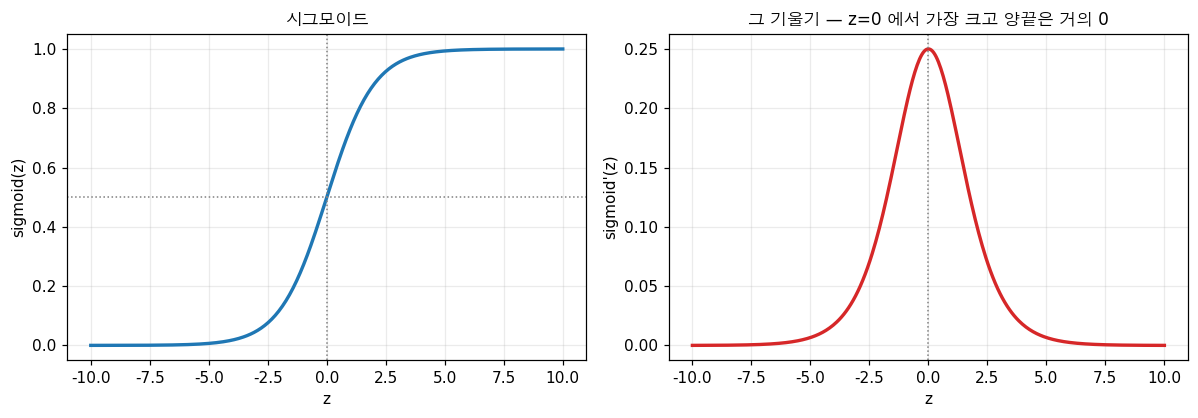

      z    sigmoid(z)         기울기   한마디
--------------------------------------------------------
    -10      0.000045    0.000045   거의 0 (둔함)
     -4      0.017986    0.017663   거의 0 (둔함)
     -1      0.268941    0.196612   민감한 구간
      0      0.500000    0.250000   가장 민감
      1      0.731059    0.196612   민감한 구간
      4      0.982014    0.017663   거의 0 (둔함)
     10      0.999955    0.000045   거의 0 (둔함)

=> 오른쪽 그림을 기억해 두세요. 기울기가 z=0 근처에만 있습니다.
   |z| 가 4 만 넘어가도 기울기가 0.018 이하로 떨어집니다.

   이게 두 가지를 설명합니다.
   6절 — 가중치를 크게 주면 z 가 커져서 계단처럼 됩니다 (양끝 평평한 구간)
   8절 — 가중치가 작으면 z 가 0 근처라 출력이 전부 0.5 근처로 뭉개집니다


In [2]:
def 시그모이드(x):
    x = max(-500.0, min(500.0, x))     # 📗 원문의 클램프. exp(1000) 은 무한대가 됩니다
    return 1.0 / (1.0 + math.exp(-x))


그림, (왼, 오) = plt.subplots(1, 2, figsize=(11, 3.9))
zs = np.linspace(-10, 10, 400)
ys = np.array([시그모이드(z) for z in zs])

왼.plot(zs, ys, lw=2.2, color="#1f77b4")
왼.axhline(0.5, color="gray", ls=":", lw=1)
왼.axvline(0, color="gray", ls=":", lw=1)
왼.set_title("시그모이드", fontsize=11)
왼.set_xlabel("z")
왼.set_ylabel("sigmoid(z)")
왼.grid(alpha=0.25)

기울기 = ys * (1 - ys)                  # 시그모이드의 도함수
오.plot(zs, 기울기, lw=2.2, color="#d62728")
오.axvline(0, color="gray", ls=":", lw=1)
오.set_title("그 기울기 — z=0 에서 가장 크고 양끝은 거의 0", fontsize=11)
오.set_xlabel("z")
오.set_ylabel("sigmoid'(z)")
오.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f"{'z':>7}{'sigmoid(z)':>14}{'기울기':>12}   한마디")
print("-" * 56)
for z in (-10, -4, -1, 0, 1, 4, 10):
    s = 시그모이드(z)
    설명 = "거의 0 (둔함)" if abs(z) >= 4 else ("가장 민감" if z == 0 else "민감한 구간")
    print(f"{z:>7}{s:>14.6f}{s*(1-s):>12.6f}   {설명}")

print(f"\n=> 오른쪽 그림을 기억해 두세요. 기울기가 z=0 근처에만 있습니다.")
print(f"   |z| 가 4 만 넘어가도 기울기가 0.018 이하로 떨어집니다.")
print(f"\n   이게 두 가지를 설명합니다.")
print(f"   6절 — 가중치를 크게 주면 z 가 커져서 계단처럼 됩니다 (양끝 평평한 구간)")
print(f"   8절 — 가중치가 작으면 z 가 0 근처라 출력이 전부 0.5 근처로 뭉개집니다")

> **👀 주목할 곳** — 오른쪽 그림. 기울기가 **z=0 근처에만 솟아 있고** 양끝은 바닥입니다.
>
> **✅ 알게 된 사실** — 시그모이드는 **z 가 0 근처일 때만 민감**합니다. |z| ≥ 4 면 기울기가 0.018 이하예요.
이 한 장이 6절(큰 가중치 → 계단)과 8절(작은 가중치 → 전부 0.5)을 동시에 설명합니다.

> **🧩 이 절의 결론**
>
> 뉴런은 **곱하고 · 더하고 · 활성화**합니다. 01단원 퍼셉트론과 활성화 함수만 다릅니다.
> 시그모이드는 **z=0 근처에서만 민감**하고 양끝은 평평합니다. 이 성질이 뒤에서 계속 나옵니다.
>
> **➡️ 다음**
>
> 부품이 다 모였습니다. 이어 붙여서 **순전파**를 만듭니다. 3절입니다.

---

## 3. 순전파 — `Layer` 와 `Network` 만들기

<sub>📗 원문 "Forward Pass" + "Step 2~3"</sub>

> 📗 원문: 딥러닝 전체에서 **가장 중요한 연산은 행렬 곱**입니다.
> 모든 층, 모든 어텐션 헤드, 모든 순전파 — **끝까지 전부 행렬 곱**이에요.
> 선형 층은 입력 벡터를 받아 가중치 행렬을 곱하고 편향 벡터를 더합니다. $y = Wx + b$.
> **그 식 하나가 신경망 연산의 90%** 입니다.

각 층에서 두 단계가 순서대로 일어납니다.

$$\begin{aligned}
z &= W \cdot \text{입력} + b \quad \text{(선형 변환)} \\
a &= \text{sigmoid}(z) \quad \text{(활성화)}
\end{aligned}$$

그리고 **한 층의 출력이 다음 층의 입력**이 됩니다. 그게 순전파의 전부입니다.

```
입력 [x1, x2]
    │
    ├─ W1 (2×3 행렬) 곱하기
    ├─ b1 (3개) 더하기
    └─ 각 원소에 sigmoid
    ▼
은닉 출력 [h1, h2, h3]
    │
    ├─ W2 (3×1 행렬) 곱하기
    ├─ b2 (1개) 더하기
    └─ sigmoid
    ▼
출력 y
```

> **실험 3** · `Layer` 와 `Network` 만들기
>
> **🎯 배울 것** — '순전파' 가 **코드로는 네 줄**이라는 걸 봅니다.
>
> **🔬 하는 일** — 📗 원문의 두 클래스를 그대로 옮기고, 2-3-1 신경망에 숫자를 통과시켜 중간값을 전부 찍어 봅니다.

In [3]:
# 📗 원문의 Layer / Network 를 그대로 옮깁니다. numpy 없이 순수 파이썬으로요
class 층:
    def __init__(self, 입력수, 뉴런수, 가중치=None, 편향=None):
        if 가중치 is not None:
            self.가중치 = 가중치
        else:
            self.가중치 = [[random.uniform(-1, 1) for _ in range(입력수)]
                        for _ in range(뉴런수)]
        self.편향 = 편향 if 편향 is not None else [0.0] * 뉴런수

    def 순전파(self, 입력):
        self.마지막입력 = 입력
        self.마지막출력 = []
        for j in range(len(self.가중치)):
            z = sum(w * x for w, x in zip(self.가중치[j], 입력))
            z += self.편향[j]
            self.마지막출력.append(시그모이드(z))
        return self.마지막출력


class 신경망:
    def __init__(self, 층들):
        self.층들 = 층들

    def 순전파(self, 입력):
        현재 = 입력
        for 층하나 in self.층들:
            현재 = 층하나.순전파(현재)      # 앞 층의 출력이 다음 층의 입력
        return 현재

    def 파라미터수(self):
        총 = 0
        for 층하나 in self.층들:
            총 += sum(len(행) for 행 in 층하나.가중치) + len(층하나.편향)
        return 총


# 2-3-1 신경망. 가중치를 눈으로 따라갈 수 있게 손으로 넣습니다
은닉층 = 층(2, 3, 가중치=[[1.0, -1.0], [0.5, 0.5], [-2.0, 1.0]], 편향=[0.0, -0.5, 1.0])
출력층 = 층(3, 1, 가중치=[[1.0, -1.0, 2.0]], 편향=[-0.5])
망 = 신경망([은닉층, 출력층])

입력하나 = [1.0, 0.5]
결과 = 망.순전파(입력하나)

print(f"입력: {입력하나}\n")
print("은닉층 — 뉴런마다 z 를 구하고 시그모이드를 통과시킵니다")
print(f"   {'뉴런':>5}{'가중치':>16}{'편향':>8}{'z':>10}{'sigmoid(z)':>13}")
print("   " + "-" * 54)
for j in range(3):
    w = 은닉층.가중치[j]
    z = sum(wi * xi for wi, xi in zip(w, 입력하나)) + 은닉층.편향[j]
    print(f"   {j:>5}{str(w):>16}{은닉층.편향[j]:>8.1f}{z:>10.3f}{시그모이드(z):>13.6f}")

print(f"\n   -> 은닉 출력 h = {[round(v, 4) for v in 은닉층.마지막출력]}\n")
print("출력층 — 그 h 를 입력으로 받습니다")
z출력 = sum(w * h for w, h in zip(출력층.가중치[0], 은닉층.마지막출력)) + 출력층.편향[0]
print(f"   가중치 {출력층.가중치[0]}, 편향 {출력층.편향[0]}")
print(f"   z = {z출력:.6f}  ->  sigmoid = {결과[0]:.6f}")

print(f"\n최종 출력: {결과[0]:.6f}")
print(f"파라미터 수: {망.파라미터수()}개  (가중치 {2*3 + 3*1}개 + 편향 {3 + 1}개)")
print(f"\n=> 📗 원문: '순전파 전체가 이겁니다. 로직 네 줄이에요.'")
print(f"   `신경망.순전파` 를 보세요. for 문 하나로 층을 차례로 통과시킬 뿐입니다.")
print(f"   층이 100개여도 코드는 그대로입니다.")

입력: [1.0, 0.5]

은닉층 — 뉴런마다 z 를 구하고 시그모이드를 통과시킵니다
      뉴런             가중치      편향         z   sigmoid(z)
   ------------------------------------------------------
       0     [1.0, -1.0]     0.0     0.500     0.622459
       1      [0.5, 0.5]    -0.5     0.250     0.562177
       2     [-2.0, 1.0]     1.0    -0.500     0.377541

   -> 은닉 출력 h = [0.6225, 0.5622, 0.3775]

출력층 — 그 h 를 입력으로 받습니다
   가중치 [1.0, -1.0, 2.0], 편향 -0.5
   z = 0.315364  ->  sigmoid = 0.578194

최종 출력: 0.578194
파라미터 수: 13개  (가중치 9개 + 편향 4개)

=> 📗 원문: '순전파 전체가 이겁니다. 로직 네 줄이에요.'
   `신경망.순전파` 를 보세요. for 문 하나로 층을 차례로 통과시킬 뿐입니다.
   층이 100개여도 코드는 그대로입니다.


> **👀 주목할 곳** — 은닉층 표의 `z` 열과 `sigmoid(z)` 열, 그리고 그 h 가 출력층 입력으로 넘어가는 것.
>
> **✅ 알게 된 사실** — 순전파는 **같은 연산(곱·합·활성화)을 층마다 반복**하는 것뿐입니다.
코드가 `for 층하나 in self.층들` 한 줄인 이유고요. 층이 100개여도 코드는 안 바뀝니다.

> **🧩 이 절의 결론**
>
> 순전파 = $z = Wx + b$ 하고 활성화, 그걸 층마다 반복. **코드로 네 줄**입니다.
> 한 층의 출력이 다음 층의 입력이 된다는 게 전부예요.
>
> **➡️ 다음**
>
> 그런데 이걸 실제로 짜면 **가장 많이 터지는 게 행렬 모양**입니다.
> 4절에서 차원 맞추는 법을 봅니다. 📗 원문이 '가장 중요한 디버깅 기술' 이라고 한 그거요.

---

## 4. 행렬 차원 추적하기

<sub>📗 원문 "Matrix Dimensions"</sub>

> 📗 원문: 차원을 추적하는 건 **딥러닝에서 단연 가장 중요한 디버깅 기술**입니다.

### 📗 2-3-1 신경망의 차원

| 단계 | 연산 | 차원 | 결과 모양 |
| --- | --- | --- | --- |
| 입력 | $x$ | — | **(2,)** |
| 은닉 선형 | $W_1 x + b_1$ | $W_1$: (3, 2), $b_1$: (3,) | **(3,)** |
| 은닉 활성화 | $\text{sigmoid}(z_1)$ | — | (3,) |
| 출력 선형 | $W_2 h + b_2$ | $W_2$: (1, 3), $b_2$: (1,) | **(1,)** |
| 출력 활성화 | $\text{sigmoid}(z_2)$ | — | (1,) |

### 🔑 규칙은 하나입니다

> **$k$ 번째 층의 가중치 행렬 $W$ 의 모양 = (이 층의 뉴런 수, 앞 층의 뉴런 수)**
>
> **행**은 지금 층에 맞추고, **열**은 앞 층에 맞춥니다.

외우는 요령이 있습니다. **"행렬 곱은 안쪽 차원이 만나서 사라진다"** 고 보면 됩니다.

$$\underbrace{(3, 2)}_{W_1} \times \underbrace{(2,)}_{x} \to (3,)$$

가운데 2 끼리 만나 없어지고 바깥의 3 이 남습니다.
그래서 $W_1$ 의 **열 수(2)가 입력 크기와 같아야** 합니다.

> 📗 원문: 모양이 안 맞으면 **버그가 있는 겁니다.**

> **실험 4** · 차원이 안 맞으면 어떻게 터지나
>
> **🎯 배울 것** — `shapes cannot be multiplied` 에러를 **미리 겪어 봅니다.** 어디를 고쳐야 하는지 알려고요.
>
> **🔬 하는 일** — 일부러 차원이 틀린 층을 만들어 터뜨리고, 에러 메시지에서 어느 숫자를 봐야 하는지 짚습니다.

In [4]:
def 모양검사(층들, 입력크기):
    # 층을 통과시키기 전에 차원이 맞는지 먼저 확인합니다
    현재 = 입력크기
    보고 = []
    for i, 층하나 in enumerate(층들):
        뉴런수 = len(층하나.가중치)
        기대입력 = len(층하나.가중치[0])
        맞음 = 기대입력 == 현재
        보고.append((i, (뉴런수, 기대입력), 현재, 뉴런수 if 맞음 else None, 맞음))
        if not 맞음:
            break
        현재 = 뉴런수
    return 보고


print("① 제대로 만든 2-3-1 신경망\n")
print(f"   {'층':>4}{'W 모양':>12}{'받는 입력':>11}{'내는 출력':>11}   판정")
print("   " + "-" * 50)
for i, W모양, 들어옴, 나감, 맞음 in 모양검사([은닉층, 출력층], 2):
    print(f"   {i:>4}{str(W모양):>12}{들어옴:>11}{str(나감):>11}   {'OK' if 맞음 else '✘ 안 맞음'}")

print("\n\n② 일부러 틀리게: 은닉층이 3개를 내는데 출력층이 4개를 기대합니다\n")
틀린출력층 = 층(4, 1, 가중치=[[1.0, 1.0, 1.0, 1.0]], 편향=[0.0])
print(f"   {'층':>4}{'W 모양':>12}{'받는 입력':>11}{'내는 출력':>11}   판정")
print("   " + "-" * 50)
for i, W모양, 들어옴, 나감, 맞음 in 모양검사([은닉층, 틀린출력층], 2):
    print(f"   {i:>4}{str(W모양):>12}{들어옴:>11}{str(나감):>11}   {'OK' if 맞음 else '✘ 안 맞음'}")

print("\n   실제로 통과시키면 어떻게 되나:")
try:
    망2 = 신경망([은닉층, 틀린출력층])
    out = 망2.순전파([1.0, 0.5])
    print(f"      터지지 않고 {out} 가 나왔습니다 (!)")
    print(f"\n   ⚠️ 순수 파이썬 `zip` 은 짧은 쪽에 맞춰 조용히 잘라 버립니다.")
    print(f"      가중치 4개 중 3개만 쓰고 넘어간 거예요. 에러도 안 납니다.")
    print(f"      numpy 나 PyTorch 였다면 여기서 바로 터졌을 겁니다. 그게 더 낫죠.")
except Exception as 오류:
    print(f"      {type(오류).__name__}: {오류}")

print(f"\n\n③ 그래서 PyTorch 식으로 터뜨리려면 길이를 직접 확인해야 합니다\n")


def 엄격한순전파(층들, 입력):
    현재 = 입력
    for i, 층하나 in enumerate(층들):
        기대 = len(층하나.가중치[0])
        if len(현재) != 기대:
            raise ValueError(
                f"{i}번 층: 가중치 행렬이 ({len(층하나.가중치)}, {기대}) 인데 "
                f"입력이 ({len(현재)},) 입니다. "
                f"W 의 열 수({기대})와 입력 길이({len(현재)})가 같아야 합니다")
        현재 = 층하나.순전파(현재)
    return 현재


try:
    엄격한순전파([은닉층, 틀린출력층], [1.0, 0.5])
except ValueError as 오류:
    print(f"   ValueError: {오류}")

print(f"\n=> 📝 에러 메시지에서 볼 숫자는 둘입니다.")
print(f"   W 의 열 수와 들어온 입력의 길이. 그 둘이 같아야 합니다.")
print(f"   PyTorch 의 'mat1 and mat2 shapes cannot be multiplied (4x2 and 3x1)' 도 같은 말이에요.")
print(f"   앞 행렬의 열(2)과 뒤 행렬의 행(3)이 안 맞는다는 뜻입니다.")

① 제대로 만든 2-3-1 신경망

      층        W 모양      받는 입력      내는 출력   판정
   --------------------------------------------------
      0      (3, 2)          2          3   OK
      1      (1, 3)          3          1   OK


② 일부러 틀리게: 은닉층이 3개를 내는데 출력층이 4개를 기대합니다

      층        W 모양      받는 입력      내는 출력   판정
   --------------------------------------------------
      0      (3, 2)          2          3   OK
      1      (1, 4)          3       None   ✘ 안 맞음

   실제로 통과시키면 어떻게 되나:
      터지지 않고 [0.8266654448822162] 가 나왔습니다 (!)

   ⚠️ 순수 파이썬 `zip` 은 짧은 쪽에 맞춰 조용히 잘라 버립니다.
      가중치 4개 중 3개만 쓰고 넘어간 거예요. 에러도 안 납니다.
      numpy 나 PyTorch 였다면 여기서 바로 터졌을 겁니다. 그게 더 낫죠.


③ 그래서 PyTorch 식으로 터뜨리려면 길이를 직접 확인해야 합니다

   ValueError: 1번 층: 가중치 행렬이 (1, 4) 인데 입력이 (3,) 입니다. W 의 열 수(4)와 입력 길이(3)가 같아야 합니다

=> 📝 에러 메시지에서 볼 숫자는 둘입니다.
   W 의 열 수와 들어온 입력의 길이. 그 둘이 같아야 합니다.
   PyTorch 의 'mat1 and mat2 shapes cannot be multiplied (4x2 and 3x1)' 도 같은 말이에요.
   앞 행렬의 열(2)과 뒤 행렬의 행(3)이 안 맞는다는 뜻입니다.


> **👀 주목할 곳** — ② 의 결과. 차원이 틀렸는데 **에러 없이 숫자가 나왔습니다.**
>
> **✅ 알게 된 사실** — 순수 파이썬 `zip` 은 짧은 쪽에 맞춰 **조용히 잘라 버립니다.** 가중치를 버리고도 멀쩡히 돌아가죠.
이런 버그가 제일 찾기 어렵습니다. numpy·PyTorch 가 바로 터뜨리는 게 **고마운 일**이에요.
에러 메시지에서 볼 숫자는 **W 의 열 수**와 **입력 길이** 둘입니다.

> **🧩 이 절의 결론**
>
> 규칙 하나입니다. **W 의 모양 = (이 층 뉴런 수, 앞 층 뉴런 수).**
> 그리고 조용히 넘어가는 것보다 **바로 터지는 게 낫습니다.** 순수 파이썬은 조용히 잘라 버리거든요.
>
> **➡️ 다음**
>
> 구조가 갖춰졌으니 01단원의 숙제를 풀어 봅니다.
> XOR 을 이번엔 `Layer`·`Network` 로요. 5절입니다.

---

## 5. 손으로 맞춘 2-2-1 로 XOR 풀기

<sub>📗 원문 "Step 4: XOR with Hand-Tuned Weights"</sub>

01단원 8절에서 OR · NAND · AND 퍼셉트론 셋으로 XOR 을 풀었습니다.
같은 일을 이번엔 **2-2-1 구조**로 합니다.

📗 원문이 쓰는 가중치입니다.

| 층 | 가중치 | 편향 | 하는 일 |
| --- | --- | --- | --- |
| 은닉 뉴런 1 | $[20, 20]$ | $-10$ | **OR 흉내** |
| 은닉 뉴런 2 | $[-20, -20]$ | $30$ | **NAND 흉내** |
| 출력 뉴런 | $[20, 20]$ | $-30$ | **AND 흉내** |

01단원과 같은 분해입니다. `(x1 OR x2) AND (x1 NAND x2)`.

> 📗 원문: **큰 가중치(20, −20)가 시그모이드를 계단 함수처럼 행동하게** 만듭니다.

왜 그런지는 6절에서 숫자로 봅니다. 일단 돌려 보죠.

> **실험 5** · 2-2-1 로 XOR
>
> **🎯 배울 것** — 01단원의 해법이 **새 구조에서도 그대로 되는지** 확인합니다.
>
> **🔬 하는 일** — 📗 원문의 가중치를 넣고 네 입력을 통과시켜, 은닉값과 최종 출력을 봅니다.

In [5]:
# 📗 원문의 가중치를 그대로 씁니다
XOR은닉 = 층(2, 2, 가중치=[[20.0, 20.0], [-20.0, -20.0]], 편향=[-10.0, 30.0])
XOR출력 = 층(2, 1, 가중치=[[20.0, 20.0]], 편향=[-30.0])
XOR망 = 신경망([XOR은닉, XOR출력])

XOR데이터 = [([0, 0], 0), ([0, 1], 1), ([1, 0], 1), ([1, 1], 0)]

print(f"{'입력':<10}{'h1 (OR쪽)':>12}{'h2 (NAND쪽)':>14}{'출력':>12}{'반올림':>8}{'정답':>7}")
print("-" * 66)
전부맞음 = True
for x, 정답 in XOR데이터:
    결과 = XOR망.순전파(x)
    h = XOR은닉.마지막출력
    예측 = 1 if 결과[0] >= 0.5 else 0
    전부맞음 &= 예측 == 정답
    print(f"{str(x):<10}{h[0]:>12.6f}{h[1]:>14.6f}{결과[0]:>12.6f}"
          f"{예측:>8}{정답:>6} {'✔' if 예측 == 정답 else '✘'}")

print(f"\nXOR 해결: {전부맞음}")
print(f"파라미터 수: {XOR망.파라미터수()}개")
print(f"\n📗 원문 출력과 대조: 0.000045 / 0.999955 / 0.999955 / 0.000045  ✔ 일치")

print(f"\n=> `h1`, `h2` 열을 보세요. 0 아니면 1 에 거의 붙어 있습니다.")
print(f"   0.000045 와 0.999955 처럼요. 시그모이드인데 계단처럼 행동하고 있습니다.")
print(f"\n   01단원 8절의 은닉 좌표와 비교해 보세요.")
print(f"   거기선 정확히 [0,1] / [1,1] / [1,1] / [1,0] 이었고,")
print(f"   여기선 [0.00, 1.00] / [1.00, 1.00] / [1.00, 1.00] / [1.00, 0.00] 입니다.")
print(f"   같은 좌표 변환을 시그모이드로 부드럽게 흉내 낸 거예요.")

입력            h1 (OR쪽)    h2 (NAND쪽)          출력     반올림     정답
------------------------------------------------------------------
[0, 0]        0.000045      1.000000    0.000045       0     0 ✔
[0, 1]        0.999955      0.999955    0.999955       1     1 ✔
[1, 0]        0.999955      0.999955    0.999955       1     1 ✔
[1, 1]        1.000000      0.000045    0.000045       0     0 ✔

XOR 해결: True
파라미터 수: 9개

📗 원문 출력과 대조: 0.000045 / 0.999955 / 0.999955 / 0.000045  ✔ 일치

=> `h1`, `h2` 열을 보세요. 0 아니면 1 에 거의 붙어 있습니다.
   0.000045 와 0.999955 처럼요. 시그모이드인데 계단처럼 행동하고 있습니다.

   01단원 8절의 은닉 좌표와 비교해 보세요.
   거기선 정확히 [0,1] / [1,1] / [1,1] / [1,0] 이었고,
   여기선 [0.00, 1.00] / [1.00, 1.00] / [1.00, 1.00] / [1.00, 0.00] 입니다.
   같은 좌표 변환을 시그모이드로 부드럽게 흉내 낸 거예요.


> **👀 주목할 곳** — `h1` 과 `h2` 열. 값이 **0.000045 아니면 0.999955** 입니다.
>
> **✅ 알게 된 사실** — 시그모이드인데 **계단처럼** 행동합니다. 가중치가 20 이라 z 가 ±10 이상으로 커지기 때문이에요.
2절 오른쪽 그림의 **평평한 양끝 구간**에 들어간 겁니다.
그래서 01단원 8절의 좌표 변환([0,1] → [1,1] → [1,1] → [1,0])을 그대로 재현합니다.

> **🧩 이 절의 결론**
>
> `Layer`·`Network` 구조로도 XOR 이 풀립니다. 📗 원문 숫자와 소수점까지 같고요.
> 은닉값이 0/1 에 거의 붙는 건 **가중치가 커서 시그모이드가 계단처럼 되기** 때문입니다.
>
> **➡️ 다음**
>
> 그러면 **가중치가 왜 하필 20 일까요?** 2 나 5 면 안 될까요?
> 6절에서 재 봅니다.

---

## 6. ⚠️ 가중치가 왜 하필 20 인가

<sub>✨ 추가 실험 — 원문은 "큰 가중치가 계단처럼 만든다" 고만 합니다</sub>

📗 원문은 한 문장으로 넘어갑니다.

> 큰 가중치(20, −20)가 시그모이드를 계단 함수처럼 행동하게 만듭니다.

**얼마나 커야 하는지**는 안 알려 줍니다. 재 봅시다.

가중치와 편향을 **전부 같은 비율로** 줄여 가며 XOR 을 통과시켜 보겠습니다.
비율을 바꿔도 **결정 경계는 그대로**입니다(01단원 5절에서 본 것처럼요).
바뀌는 건 **출력이 얼마나 확신에 차 있느냐** 뿐이고요.

> **실험 6** · ⚠️ 가중치 크기를 줄여 가며
>
> **🎯 배울 것** — '큰 가중치' 가 **얼마나 커야** 하는지, 작으면 **정확히 뭐가 깨지는지** 봅니다.
>
> **🔬 하는 일** — XOR 의 모든 가중치·편향에 같은 배율을 곱해 1배에서 100배까지 바꾸며 출력을 봅니다.

In [6]:
# ✨ 추가 — 가중치 전체에 같은 배율을 곱합니다
def 배율XOR(배율):
    k = 배율 / 20.0
    은 = 층(2, 2, 가중치=[[20 * k, 20 * k], [-20 * k, -20 * k]],
          편향=[-10 * k, 30 * k])
    출 = 층(2, 1, 가중치=[[20 * k, 20 * k]], 편향=[-30 * k])
    return 신경망([은, 출])


print("가중치 배율만 바꿉니다. 경계는 그대로, 확신만 달라집니다.\n")
print(f"{'배율':>6}{'[0,0]':>11}{'[0,1]':>11}{'[1,0]':>11}{'[1,1]':>11}"
      f"{'맞힌 수':>9}{'0.5 까지 최소 거리':>20}")
print("-" * 88)
for 배율 in (1, 2, 5, 10, 20, 50, 100):
    망3 = 배율XOR(배율)
    출력들 = [망3.순전파(x)[0] for x, _ in XOR데이터]
    맞음 = sum((1 if v >= 0.5 else 0) == t for v, (_, t) in zip(출력들, XOR데이터))
    최소거리 = min(abs(v - 0.5) for v in 출력들)
    print(f"{배율:>6}" + "".join(f"{v:>11.5f}" for v in 출력들)
          + f"{맞음:>8}/4{최소거리:>20.5f}")

print(f"\n=> ⚠️ 배율 2 이하에서는 4개 중 2개만 맞습니다.")
print(f"   출력이 전부 0.36~0.49 사이로 뭉개져서 `>= 0.5` 판정이 제대로 안 갈리거든요.")
print(f"\n   맨 오른쪽 열을 보세요. 배율 1 일 때 0.5 까지의 거리가 0.064 입니다.")
print(f"   네 출력이 전부 0.5 바로 옆에 붙어 있다는 뜻이에요. 사실상 '모르겠다' 입니다.")
print(f"   배율 20 이면 그 거리가 0.49995 로 벌어집니다. 확신에 차 있죠.")
print(f"\n   📝 그러니 '큰 가중치' 의 기준은 z 가 시그모이드의 평평한 구간에 들어가는 크기입니다.")
print(f"   2절 표에서 |z| >= 4 면 기울기가 0.018 이하였죠.")
print(f"   가중치 20 에 입력 1 이면 z 가 ±10 이라 충분히 평평한 데로 갑니다.")
print(f"\n   💡 그런데 학습 관점에서는 이게 문제이기도 합니다.")
print(f"   평평하다 = 기울기가 0 이다 = 학습 신호가 안 흐른다 는 뜻이거든요.")
print(f"   손으로 넣을 땐 좋지만 학습시킬 땐 독입니다. 03단원에서 다시 만납니다.")

가중치 배율만 바꿉니다. 경계는 그대로, 확신만 달라집니다.

    배율      [0,0]      [0,1]      [1,0]      [1,1]     맞힌 수        0.5 까지 최소 거리
----------------------------------------------------------------------------------------
     1    0.42436    0.43657    0.43657    0.42436       2/4             0.06343
     2    0.36425    0.48107    0.48107    0.36425       2/4             0.01893
     5    0.10684    0.85087    0.85087    0.10684       4/4             0.35087
    10    0.00715    0.99236    0.99236    0.00715       4/4             0.49236
    20    0.00005    0.99995    0.99995    0.00005       4/4             0.49995
    50    0.00000    1.00000    1.00000    0.00000       4/4             0.50000
   100    0.00000    1.00000    1.00000    0.00000       4/4             0.50000

=> ⚠️ 배율 2 이하에서는 4개 중 2개만 맞습니다.
   출력이 전부 0.36~0.49 사이로 뭉개져서 `>= 0.5` 판정이 제대로 안 갈리거든요.

   맨 오른쪽 열을 보세요. 배율 1 일 때 0.5 까지의 거리가 0.064 입니다.
   네 출력이 전부 0.5 바로 옆에 붙어 있다는 뜻이에요. 사실상 '모르겠다' 입니다.
   배율 20 이면 그 거리가 0.49995 로 벌어집니다. 확신에 차

> **👀 주목할 곳** — `맞힌 수` 열이 배율 2 와 5 사이에서 **2/4 에서 4/4 로** 바뀌는 지점.
>
> **✅ 알게 된 사실** — ⚠️ 가중치가 작으면 출력이 전부 **0.5 근처로 뭉개져서** 판정이 안 갈립니다. 배율 1 에서 가장 애매한 값이 0.43 이에요.
'큰 가중치' 의 기준은 **z 를 시그모이드의 평평한 구간(|z| ≥ 4)으로 밀어 넣는 크기**입니다.
다만 평평하다는 건 **기울기가 0** 이라는 뜻이라, 학습할 때는 오히려 독입니다. 03단원에서 다시 봅니다.

> **🧩 이 절의 결론**
>
> ⚠️ '큰 가중치' 의 기준은 **z 를 시그모이드의 평평한 구간으로 밀어 넣는 크기**입니다.
> 작으면 출력이 0.5 근처로 뭉개져 판정이 안 갈립니다. 배율 2 이하는 4개 중 2개만 맞았습니다.
> 그리고 그 '평평함' 은 학습에는 독입니다. 기울기가 없으니까요.
>
> **➡️ 다음**
>
> XOR 은 네 점짜리 장난감입니다. **진짜 곡선이 필요한 문제**를 가져와 봅니다. 7절입니다.

---

## 7. 원 분류 — 곡선이 필요한 문제

<sub>📗 원문 "Step 5: Circle Classification"</sub>

2차원 점을 **반지름 0.5 짜리 원의 안/밖**으로 분류합니다.

$$\text{정답} = \begin{cases} 1 & x^2 + y^2 < 0.25 \text{ 이면 (안쪽)} \\ 0 & \text{아니면 (바깥)} \end{cases}$$

> 📗 원문: 이건 **곡선 결정 경계**가 필요합니다. 단일 퍼셉트론으로는 불가능해요.

XOR 은 점이 네 개뿐이라 "어쩌다 된 거 아니냐" 싶을 수 있습니다.
원 분류는 점이 200개고 **경계가 진짜로 둥급니다.**

> **실험 7** · 원 데이터 만들고 들여다보기
>
> **🎯 배울 것** — 무작위 가중치 실험(8절)에 들어가기 전에 **데이터가 어떻게 생겼는지** 확인합니다.
>
> **🔬 하는 일** — 📗 원문대로 200점을 만들고 그려 봅니다. 클래스 비율도 세어 둡니다. 8절에서 쓸 숫자예요.

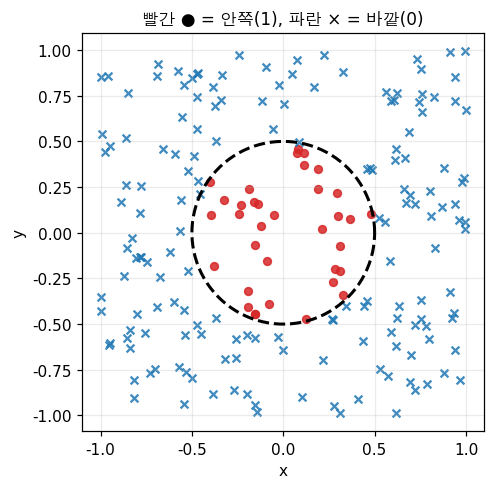

200점 중 안쪽 35개, 바깥 165개
   안쪽 비율 17.5%, 바깥 비율 82.5%

=> ⚠️ 이 두 숫자를 기억해 두세요. 8절에서 다시 나옵니다.
   '아무거나 다수 클래스로 찍기' 의 정확도가 82.5% 라는 뜻이기도 합니다.

   점선이 정답 경계입니다. 직선으로는 절대 못 그립니다.
   그래서 01단원의 퍼셉트론 하나로는 손도 못 대는 문제예요.


In [7]:
# 📗 원문의 데이터 생성 (seed 42)
random.seed(42)
원데이터 = []
for _ in range(200):
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)
    정답 = 1 if (x * x + y * y) < 0.25 else 0
    원데이터.append(([x, y], 정답))

안쪽수 = sum(t for _, t in 원데이터)
바깥수 = len(원데이터) - 안쪽수

plt.figure(figsize=(4.6, 4.6))
for (x, y), 정답 in 원데이터:
    plt.scatter(x, y, s=26, c="#d62728" if 정답 else "#1f77b4",
                marker="o" if 정답 else "x", alpha=0.85)
각도 = np.linspace(0, 2 * np.pi, 200)
plt.plot(0.5 * np.cos(각도), 0.5 * np.sin(각도), "k--", lw=2)
plt.title("빨간 ● = 안쪽(1), 파란 × = 바깥(0)", fontsize=11)
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"200점 중 안쪽 {안쪽수}개, 바깥 {바깥수}개")
print(f"   안쪽 비율 {안쪽수/200:.1%}, 바깥 비율 {바깥수/200:.1%}")
print(f"\n=> ⚠️ 이 두 숫자를 기억해 두세요. 8절에서 다시 나옵니다.")
print(f"   '아무거나 다수 클래스로 찍기' 의 정확도가 {바깥수/200:.1%} 라는 뜻이기도 합니다.")
print(f"\n   점선이 정답 경계입니다. 직선으로는 절대 못 그립니다.")
print(f"   그래서 01단원의 퍼셉트론 하나로는 손도 못 대는 문제예요.")

> **👀 주목할 곳** — `안쪽 비율 17.5%` 와 `바깥 비율 82.5%`.
>
> **✅ 알게 된 사실** — 두 비율이 **8절의 두 숫자**가 됩니다. 미리 적어 두고 가세요.
그리고 점선 경계가 **둥급니다.** 직선 하나로는 손도 못 대는 문제입니다.

---

## 8. ⚠️ 학습 전 신경망은 입력을 무시합니다

<sub>📗 원문 "Random weights give poor accuracy" + ✨ 반증</sub>

이제 2-8-1 신경망에 **무작위 가중치**를 넣고 원 데이터를 통과시킵니다.

📗 원문의 설명입니다.

> 무작위 가중치로는 분류가 잘 안 됩니다. 하지만 **순전파는 여전히 돌아갑니다.**
> 그게 요점이에요. 순전파는 그냥 계산입니다.
>
> 무작위 가중치는 정확도가 나쁩니다. **종종 다수 클래스를 찍는 것보다도 못합니다.**

📗 원문이 얻은 숫자는 **17.5%** 입니다.
7절에서 적어 둔 숫자와 비교해 보세요. **안쪽 비율과 똑같습니다.**

우연일까요?

> **실험 8** · ⚠️ 무작위 가중치로 100번 돌려 보기
>
> **🎯 배울 것** — '무작위 가중치의 정확도' 라는 숫자가 **무엇을 뜻하는지** 정확히 알아봅니다.
>
> **🔬 하는 일** — 시드를 100가지로 바꿔 가며 2-8-1 신경망의 정확도를 재고, 그때 신경망이 **실제로 뭐라고 답했는지** 같이 셉니다.

In [8]:
# ✨ 추가 — 시드를 바꿔 가며 100번
정확도들 = []
한클래스만 = 0
for 시드 in range(100):
    random.seed(1000 + 시드)
    망4 = 신경망([층(2, 8), 층(8, 1)])
    예측 = [1 if 망4.순전파(x)[0] >= 0.5 else 0 for x, _ in 원데이터]
    맞음 = sum(p == t for p, (_, t) in zip(예측, 원데이터))
    정확도들.append(round(맞음 / 200, 3))
    if len(set(예측)) == 1:
        한클래스만 += 1

세기 = Counter(정확도들)
print("무작위 가중치 2-8-1 신경망, 시드 100가지\n")
print(f"{'정확도':>9}{'횟수':>7}   그때 신경망이 한 일")
print("-" * 54)
보여준것 = sorted(세기.items(), key=lambda t: -t[1])[:6]
for 정확도, 횟수 in 보여준것:
    뜻 = ("200점 전부 '바깥' 이라 답함" if 정확도 == 0.825 else
         "200점 전부 '안쪽' 이라 답함" if 정확도 == 0.175 else "섞여서 답함")
    print(f"{정확도:>9.1%}{횟수:>7}   {뜻}")
print(f"{'(나머지)':>9}{100 - sum(v for _, v in 보여준것):>7}   제각각")
print("-" * 54)

print(f"\n200점 전부를 같은 클래스로 답한 경우: {한클래스만}/100 회")
print(f"정확도 최소 {min(정확도들):.1%}, 중앙값 {statistics.median(정확도들):.1%}, 최대 {max(정확도들):.1%}")

print(f"\n=> ⚠️ 정확도가 17.5% 와 82.5% 두 곳에 몰려 있습니다.")
print(f"   7절에서 적어 둔 안쪽 비율·바깥 비율 그대로예요.")
print(f"\n   📗 원문은 17.5% 를 얻어 '무작위는 성능이 나쁘다' 고 했습니다.")
print(f"   그런데 시드를 바꾸면 82.5% 도 32번 나옵니다. 다수 클래스 찍기와 같은 점수죠.")
print(f"   숫자만 보면 하나는 '형편없고' 하나는 '괜찮아' 보입니다.")
print(f"\n   그런데 둘은 완전히 같은 상태입니다. 둘 다 한 클래스만 답한 거예요.")
print(f"   어느 쪽이 나오느냐는 출력이 0.5 의 위에 떨어지냐 아래에 떨어지냐 뿐입니다.")

무작위 가중치 2-8-1 신경망, 시드 100가지

      정확도     횟수   그때 신경망이 한 일
------------------------------------------------------
    17.5%     43   200점 전부 '안쪽' 이라 답함
    82.5%     32   200점 전부 '바깥' 이라 답함
    81.5%      2   섞여서 답함
    46.0%      1   섞여서 답함
    71.5%      1   섞여서 답함
    54.5%      1   섞여서 답함
    (나머지)     20   제각각
------------------------------------------------------

200점 전부를 같은 클래스로 답한 경우: 75/100 회
정확도 최소 17.5%, 중앙값 44.5%, 최대 82.5%

=> ⚠️ 정확도가 17.5% 와 82.5% 두 곳에 몰려 있습니다.
   7절에서 적어 둔 안쪽 비율·바깥 비율 그대로예요.

   📗 원문은 17.5% 를 얻어 '무작위는 성능이 나쁘다' 고 했습니다.
   그런데 시드를 바꾸면 82.5% 도 32번 나옵니다. 다수 클래스 찍기와 같은 점수죠.
   숫자만 보면 하나는 '형편없고' 하나는 '괜찮아' 보입니다.

   그런데 둘은 완전히 같은 상태입니다. 둘 다 한 클래스만 답한 거예요.
   어느 쪽이 나오느냐는 출력이 0.5 의 위에 떨어지냐 아래에 떨어지냐 뿐입니다.


In [9]:
# ✨ 추가 — 왜 한 클래스만 답하나: 출력이 거의 안 변합니다
print("입력이 (-1, 1) 을 다 돌아다니는데 출력은 얼마나 변할까요\n")
print(f"{'시드':>7}{'출력 최소':>12}{'출력 최대':>12}{'출력 폭':>11}"
      f"{'1 이라 답한 수':>15}{'정확도':>9}")
print("-" * 70)
for 시드 in (1000, 1001, 1003, 1007, 1011):
    random.seed(시드)
    망5 = 신경망([층(2, 8), 층(8, 1)])
    출력들 = [망5.순전파(x)[0] for x, _ in 원데이터]
    예측 = [1 if v >= 0.5 else 0 for v in 출력들]
    맞음 = sum(p == t for p, (_, t) in zip(예측, 원데이터))
    print(f"{시드:>7}{min(출력들):>12.4f}{max(출력들):>12.4f}"
          f"{max(출력들)-min(출력들):>11.4f}{sum(예측):>15}{맞음/200:>9.1%}")

print(f"\n=> `출력 폭` 열을 보세요. 전부 0.1 안팎입니다.")
print(f"   입력은 (-1,1) × (-1,1) 사각형 전체를 돌아다니는데 말이죠.")
print(f"\n   왜냐면 2절에서 본 그 이유입니다.")
print(f"   편향이 0 이고 가중치가 (-1,1) 이라 z 가 0 근처에 머뭅니다.")
print(f"   은닉층 출력이 전부 0.5 언저리가 되고, 그게 출력층에서도 좁은 범위로 나옵니다.")
print(f"\n   📝 그래서 정확히 말하면 이렇습니다.")
print(f"      학습 전 신경망은 '틀리는' 게 아니라 '입력을 보지 않습니다'.")
print(f"      무엇을 넣든 거의 같은 값을 뱉습니다. 그걸 0.5 로 자르니 한 클래스만 나오고요.")
print(f"\n   💡 그리고 이게 정확도라는 지표의 함정이기도 합니다.")
print(f"      82.5% 는 Phase 2 17단원에서 본 그 함정이에요.")
print(f"      아무것도 안 하는 모델이 다수 클래스 비율만큼 점수를 받습니다.")

입력이 (-1, 1) 을 다 돌아다니는데 출력은 얼마나 변할까요

     시드       출력 최소       출력 최대       출력 폭      1 이라 답한 수      정확도
----------------------------------------------------------------------
   1000      0.6431      0.7311     0.0881            200    17.5%
   1001      0.7387      0.8836     0.1449            200    17.5%
   1003      0.0807      0.1835     0.1028              0    82.5%
   1007      0.8616      0.8944     0.0328            200    17.5%
   1011      0.5288      0.6918     0.1629            200    17.5%

=> `출력 폭` 열을 보세요. 전부 0.1 안팎입니다.
   입력은 (-1,1) × (-1,1) 사각형 전체를 돌아다니는데 말이죠.

   왜냐면 2절에서 본 그 이유입니다.
   편향이 0 이고 가중치가 (-1,1) 이라 z 가 0 근처에 머뭅니다.
   은닉층 출력이 전부 0.5 언저리가 되고, 그게 출력층에서도 좁은 범위로 나옵니다.

   📝 그래서 정확히 말하면 이렇습니다.
      학습 전 신경망은 '틀리는' 게 아니라 '입력을 보지 않습니다'.
      무엇을 넣든 거의 같은 값을 뱉습니다. 그걸 0.5 로 자르니 한 클래스만 나오고요.

   💡 그리고 이게 정확도라는 지표의 함정이기도 합니다.
      82.5% 는 Phase 2 17단원에서 본 그 함정이에요.
      아무것도 안 하는 모델이 다수 클래스 비율만큼 점수를 받습니다.


> **👀 주목할 곳** — 두 번째 표의 `출력 폭` 열. 전부 **0.1 안팎**입니다.
>
> **✅ 알게 된 사실** — ⚠️ 학습 전 신경망은 **틀리는 게 아니라 입력을 보지 않습니다.** 뭘 넣든 거의 같은 값을 뱉어요.
그래서 정확도가 **17.5% 아니면 82.5%** 로 갈립니다. 출력이 0.5 위에 떨어지냐 아래냐 차이일 뿐이죠.
📗 원문의 17.5% 와 제가 얻은 82.5% 는 **같은 상태**입니다.
그러니 이 숫자로 '성능이 나쁘다' 고 말하는 건 정확하지 않습니다. **아직 성능이랄 게 없는** 거예요.

> **🧩 이 절의 결론**
>
> ⚠️ 무작위 가중치 신경망의 정확도는 **의미가 없습니다.** 17.5% 든 82.5% 든 같은 상태예요.
> 출력 폭이 0.1 밖에 안 돼서 **입력을 사실상 무시**하기 때문입니다.
> 그리고 82.5% 는 다수 클래스 찍기와 같은 점수라, 숫자만 보면 속기 쉽습니다.
>
> **➡️ 다음**
>
> 그럼 가중치를 제대로 찾으면 뭐까지 할 수 있을까요?
> 9절에서 **이론적 한계**를 보고, 층을 몇 개 쌓을지 이야기합니다.

---

## 9. ⚠️ 보편 근사와 '깊게 vs 넓게'

<sub>📗 원문 "Universal Approximation Theorem" + ✨ 측정</sub>

> 📗 1989년, George Cybenko 가 놀라운 걸 증명했습니다.
> **은닉층 하나에 뉴런이 충분히 많으면,
> 어떤 연속 함수든 원하는 정확도로 근사할 수 있습니다.**

### 🔑 이 정리를 오해하면 안 됩니다

| 정리가 말하는 것 | 정리가 말하지 않는 것 |
| --- | --- |
| 은닉층 하나로 **가능하다** | 은닉층 하나가 **최선이다** |
| 뉴런이 충분히 많으면 | **얼마나** 많아야 하는지 |
| 근사하는 가중치가 **존재한다** | 그 가중치를 **찾을 수 있다** |

> 📗 원문: 이건 은닉층 하나가 항상 최선이라는 뜻이 **아닙니다.**
> 구조가 **이론적으로 가능하다**는 뜻이죠.
> 실제로는 더 깊은 신경망이 같은 함수를
> **얕고 넓은 것보다 훨씬 적은 파라미터로** 배웁니다.

마지막 문장을 재 봅시다. **정말 항상 그럴까요?**

> **실험 9** · ⚠️ 깊게 vs 넓게, 파라미터 수 비교
>
> **🎯 배울 것** — '깊은 게 파라미터가 적다' 가 **언제 맞는 말인지** 확인합니다.
>
> **🔬 하는 일** — 은닉 뉴런 총수를 384개로 고정하고, 넓게(한 층) vs 깊게(두 층) 쌓을 때의 파라미터 수를 입력 차원별로 비교합니다.

In [10]:
# ✨ 추가 — 파라미터 수를 세는 함수
def 파라미터수(구조):
    # 구조 예: [784, 256, 128, 10]
    return sum(앞 * 뒤 + 뒤 for 앞, 뒤 in zip(구조, 구조[1:]))


print("📗 연습문제 3번 — 유명한 구조들의 파라미터 수\n")
print(f"{'구조':<24}{'파라미터':>13}")
print("-" * 38)
for 구조 in ([2, 2, 1], [2, 8, 1], [784, 30, 10], [784, 128, 10], [784, 256, 128, 10]):
    print(f"{'-'.join(map(str, 구조)):<24}{파라미터수(구조):>13,}")
print(f"\n   맨 아랫줄이 📗 연습문제 3번의 MNIST 구조입니다. 235,146개예요.")

print(f"\n\n⚠️ 은닉 뉴런을 384개 쓰되, 넓게 vs 깊게\n")
print(f"{'입력 차원':>9}{'넓게 (한 층)':>18}{'파라미터':>12}"
      f"{'깊게 (두 층)':>20}{'파라미터':>12}   싼 쪽")
print("-" * 88)
for 입력, 출력 in [(2, 1), (10, 1), (100, 10), (784, 10), (4096, 10)]:
    넓게 = [입력, 384, 출력]
    깊게 = [입력, 256, 128, 출력]
    a, b = 파라미터수(넓게), 파라미터수(깊게)
    print(f"{입력:>9}{'-'.join(map(str, 넓게)):>18}{a:>12,}"
          f"{'-'.join(map(str, 깊게)):>20}{b:>12,}   "
          f"{'깊게' if b < a else '넓게'}")

print(f"\n=> ⚠️ 입력 차원에 따라 뒤집힙니다.")
print(f"   입력이 2~100 차원이면 넓게가 쌉니다. 784 이상이면 깊게가 싸고요.")
print(f"\n   왜냐면 연결 수가 이렇게 생겼거든요.")
print(f"      입력 -> 은닉 : (입력 차원 × 뉴런 수)")
print(f"      은닉 -> 은닉 : (뉴런 수 × 뉴런 수)")
print(f"\n   입력 차원이 뉴런 수보다 작으면 첫 층이 싸니까 한 층에 몰아넣는 게 이득이고,")
print(f"   입력 차원이 크면 첫 층이 비싸니까 뉴런을 줄이고 층을 쌓는 게 이득입니다.")
print(f"\n   📝 그러니 📗 원문의 '깊은 게 파라미터가 적다' 는")
print(f"      입력 차원이 클 때 맞는 말입니다. 이미지·텍스트가 그런 경우죠.")
print(f"      이 노트북의 2입력 예제에서는 정반대입니다.")
print(f"\n   ⚠️ 그리고 한 가지 더. 여기서는 파라미터 수만 셌습니다.")
print(f"      '같은 함수를 배운다' 는 건 학습을 시켜 봐야 아는데,")
print(f"      이 단원에는 학습이 없습니다. 그건 03단원 몫이에요.")

📗 연습문제 3번 — 유명한 구조들의 파라미터 수

구조                               파라미터
--------------------------------------
2-2-1                               9
2-8-1                              33
784-30-10                      23,860
784-128-10                    101,770
784-256-128-10                235,146

   맨 아랫줄이 📗 연습문제 3번의 MNIST 구조입니다. 235,146개예요.


⚠️ 은닉 뉴런을 384개 쓰되, 넓게 vs 깊게

    입력 차원          넓게 (한 층)        파라미터            깊게 (두 층)        파라미터   싼 쪽
----------------------------------------------------------------------------------------
        2           2-384-1       1,537         2-256-128-1      33,793   넓게
       10          10-384-1       4,609        10-256-128-1      35,841   넓게
      100        100-384-10      42,634      100-256-128-10      60,042   넓게
      784        784-384-10     305,290      784-256-128-10     235,146   깊게
     4096       4096-384-10   1,577,098     4096-256-128-10   1,083,018   깊게

=> ⚠️ 입력 차원에 따라 뒤집힙니다.
   입력이 2~100 차원이면 넓게가 쌉니다. 784 이상이면 깊게가 싸고요.

   왜

> **👀 주목할 곳** — `싼 쪽` 열이 입력 100 과 784 사이에서 **'넓게' 에서 '깊게' 로** 바뀌는 것.
>
> **✅ 알게 된 사실** — ⚠️ '깊은 게 파라미터가 적다' 는 **입력 차원이 클 때만** 맞습니다.
입력→은닉은 (입력 × 뉴런)이고 은닉→은닉은 (뉴런 × 뉴런)이라, 어느 쪽이 큰지에 달렸거든요.
이 노트북의 2입력 예제에서는 **넓게가 20배 넘게 쌉니다.**
그리고 여기서 센 건 파라미터 수뿐입니다. **성능 비교는 학습이 있어야** 하고, 그건 03단원입니다.

### 📗 조립해서 쓰기

> 📗 원문: 신경망은 **조립 가능**합니다. 쌓고, 잇고, 나란히 돌릴 수 있어요.

| 모델 | 구조 |
| --- | --- |
| **Whisper** | 오디오를 처리하는 **인코더** + 텍스트를 생성하는 **디코더** |
| 요즘 **LLM** | 디코더만 |
| **BERT** | 인코더만 |
| **T5** | 인코더-디코더 |

> 📗 원문: **구조 선택이 모델이 할 수 있는 일을 정합니다.**

지금은 `Layer` 를 리스트에 넣는 수준이지만, 원리는 같습니다.
`신경망([층, 층, 층])` 에서 리스트 자리에 **다른 신경망을 넣으면** 그게 조립이에요.

> **🧩 이 절의 결론**
>
> 은닉층 하나로도 **이론적으로는** 어떤 연속 함수든 근사할 수 있습니다(보편 근사 정리).
> 다만 '가능하다' 와 '최선이다' 와 '찾을 수 있다' 는 다 다른 말입니다.
> ⚠️ 그리고 '깊은 게 파라미터가 적다' 는 **입력 차원이 클 때만** 맞습니다.
>
> **➡️ 다음**
>
> 10절에서 정리합니다.
> 그리고 이 단원 내내 미뤄 둔 것 — **가중치를 어떻게 찾나** — 가 03단원입니다.

---

## 10. 정리

### ⚠️ 이 노트북에서 원문과 달랐던 것

| 📗 원문 | 측정 결과 | 절 |
| --- | --- | --- |
| "무작위 가중치는 정확도가 나쁩니다. 종종 다수 클래스를 찍는 것보다도 못합니다" (17.5%) | ⚠️ **시드를 바꾸면 82.5% 도 32/100 회 나옵니다.** 둘 다 '200점을 한 클래스로 답한' 같은 상태예요. 출력 폭이 0.1 뿐이라 **입력을 사실상 무시**합니다 | 8 |
| "더 깊은 신경망이 같은 함수를 **훨씬 적은 파라미터로** 배운다" | ⚠️ **입력 차원이 클 때만** 그렇습니다. 입력 2차원에서는 넓게 쓰는 쪽이 20배 넘게 쌉니다. 뒤집히는 지점은 입력 100~784 차원 사이 | 9 |

### ✨ 원문에 없는데 재 본 것

| 질문 | 측정 결과 | 절 |
| --- | --- | --- |
| '큰 가중치' 는 얼마나 커야 하나 | 배율 **2 이하면 4개 중 2개만** 맞힙니다. 출력이 0.43~0.5 로 뭉개져서요 | 6 |
| 차원이 안 맞으면 터지나 | ⚠️ 순수 파이썬 `zip` 은 **조용히 잘라 버립니다.** 에러도 없이 틀린 답이 나와요 | 4 |
| 384개 뉴런을 어떻게 배치할까 | 입력 2·10·100 차원은 넓게, 784·4096 차원은 깊게가 쌉니다 | 9 |

### ✅ 측정으로 확인된 원문의 주장

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| 2-2-1 + 가중치 20/−20 으로 XOR 이 풀린다 | ✅ 0.000045 / 0.999955 소수점까지 일치 | 5 |
| 큰 가중치가 시그모이드를 계단처럼 만든다 | ✅ 은닉값이 0.000045 와 0.999955 로 양끝에 붙음 | 5·6 |
| 784-256-128-10 의 파라미터 수 | ✅ 235,146개 | 9 |
| 순전파는 학습 없이도 돌아간다 | ✅ 무작위 가중치로도 끝까지 계산됨 | 8 |

### 🔑 한 줄로 꿰면

> **층 하나 = 행렬 곱 + 편향 + 활성화.**
> 그걸 이어 붙인 게 순전파고, **차원만 맞으면 돌아갑니다.**
> 다만 **돌아가는 것과 쓸모 있는 것은 다릅니다.**

8절이 그 마지막 문장입니다.
무작위 가중치 신경망도 **완벽하게 돌아갑니다.** 끝까지 계산해서 숫자를 내놓아요.
그런데 **입력을 보지 않습니다.**

| 이 단원이 남긴 숙제 | 어디서 |
| --- | --- |
| 쓸모 있는 가중치를 **어떻게 찾나** | **03단원** (역전파) |
| 시그모이드의 평평한 구간이 학습을 막는 문제 | **04단원** (활성화 함수) |

---

## 🔧 PyTorch 로는

<sub>📗 원문 "Use It"</sub>

> 📗 원문: PyTorch 는 위의 모든 걸 **네 줄**로 합니다.

```python
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(2, 8),
    nn.Sigmoid(),
    nn.Linear(8, 1),
    nn.Sigmoid(),
)

x = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
print(model(x))
```

### 이 노트북과 하나씩 대응됩니다

| 이 노트북 | PyTorch | 하는 일 |
| --- | --- | --- |
| `층(2, 8)` | `nn.Linear(2, 8)` | 가중치 (8, 2) + 편향 (8,) |
| `시그모이드` | `nn.Sigmoid()` | 원소마다 적용 |
| `신경망([...])` | `nn.Sequential(...)` | 층을 순서대로 이어 붙임 |
| `망.파라미터수()` | `sum(p.numel() for p in model.parameters())` | 파라미터 세기 |

> 📗 원문: 차이는 **속도와 규모**입니다.
> PyTorch 는 GPU 에서 돌고, 수백만 개짜리 배치를 처리하고,
> **역전파용 기울기를 자동으로 계산**합니다.
> 하지만 **순전파 로직은 방금 밑바닥부터 만든 것과 동일합니다.**

### 🔑 한 가지 차이는 짚고 가세요

PyTorch 의 `nn.Linear` 는 가중치를 **0 이 아니라 특정 분포**로 초기화합니다.
8절에서 본 "출력이 전부 0.5 근처" 문제를 줄이려고요.
그 초기화 방식이 **08단원(가중치 초기화)** 의 주제입니다.

---

## 🚀 Ship It — `prompt-network-architect.md`

<sub>📗 원문 저장소의 `02-multi-layer-networks/outputs/prompt-network-architect.md` (82줄)</sub>

> 📗 원문: 구조를 설계할 때 쓰는 프롬프트입니다.
> **층을 몇 개, 층당 뉴런을 몇 개, 어떤 활성화 함수**를 쓸지 정할 때요.

### 묻는 순서

| 순서 | 질문 | 이 단원의 근거 |
| --- | --- | --- |
| 1 | 입력이 **몇 차원**인가 | 9절 — 깊게/넓게가 여기서 갈립니다 |
| 2 | 경계가 **직선인가 곡선인가** | 01단원 7절 · 이 단원 7절 |
| 3 | 출력이 **몇 개**인가 | 이진이면 1개, 다중 분류면 클래스마다 1개 |
| 4 | 파라미터 **예산**이 있나 | 9절의 파라미터 계산 |

### ✨ 추가 — 측정 뒤에 제가 덧붙인 두 가지

```markdown
## 구조를 정할 때 (⚠️ 9절)

"깊게 쌓는 게 파라미터가 적다" 를 기본값으로 삼지 마세요.
입력 차원에 따라 뒤집힙니다.

- 입력 차원이 뉴런 수보다 작으면 -> 넓게가 쌈 (측정: 2차원에서 20배 차이)
- 입력 차원이 크면 -> 깊게가 쌈 (측정: 784차원에서 23% 절약)

이미지·텍스트는 후자이고, 표 형태 데이터는 전자인 경우가 많습니다.

## 학습 전 모델의 정확도를 볼 때 (⚠️ 8절)

그 숫자는 **의미가 없습니다.** 해석하려 들지 마세요.
측정에서 같은 구조가 시드에 따라 17.5% 와 82.5% 를 오갔고,
둘 다 '모든 입력에 같은 답' 을 한 상태였습니다.

대신 이걸 보세요. **출력값의 폭.**
입력을 바꿔도 출력이 거의 안 변하면 (측정: 폭 0.1)
그 신경망은 아직 입력을 보지 않고 있는 겁니다.
```

---

## 📚 용어 정리

<sub>📗 원문 "Key Terms" — 설명은 쉬운 말로 다시 썼습니다</sub>

| 용어 | 흔히 하는 말 | 진짜 무슨 뜻인가 |
| --- | --- | --- |
| **순전파** | "모델 돌리기" | 입력을 모든 층에 통과시켜 출력을 만드는 것. 곱하고·더하고·활성화 |
| **은닉층** | "중간 부분" | 입력도 출력도 아닌 층. **그 값을 데이터에서 직접 본 적이 없어서** 은닉입니다 |
| **은닉 상태** | "중간 표현" | 한 층이 내놓는 숫자 벡터. 텍스트는 차원을 늘리고 이미지는 줄입니다 |
| **다층 신경망** | "딥러닝" | 층을 차례로 쌓아 각 층의 출력이 다음 층의 입력이 되는 것 |
| **활성화 함수** | "비선형성" | 선형 변환 뒤에 붙어 **결정 경계에 곡선을 넣는** 함수 |
| **시그모이드** | "S 곡선" | $1/(1+e^{-z})$. 어떤 실수든 (0,1) 로 눌러 담고 **어디서나 미분 가능**합니다 |
| **가중치 행렬** | "파라미터" | 모양이 **(이 층 뉴런 수, 앞 층 뉴런 수)** 인 행렬 |
| **편향 벡터** | "오프셋" | 행렬 곱 뒤에 더해, 입력이 전부 0 이어도 뉴런이 반응할 수 있게 합니다 |
| **선형 변환** | "행렬 곱 단계" | $z = Wx + b$. 활성화 전의 계산 |
| **보편 근사 정리** | "신경망은 뭐든 배운다" | 은닉층 하나 + 충분한 뉴런으로 어떤 연속 함수든 근사 가능. 단 **'충분히' 가 수십억일 수도** |
| **결정 경계** | "분류가 뒤집히는 곳" | 출력이 분류 임곗값을 가로지르는 입력 공간상의 면 |

---

## 📖 더 읽을 것

<sub>📗 원문 "Further Reading"</sub>

- **Michael Nielsen, *Neural Networks and Deep Learning* 1~2장**
  (<http://neuralnetworksanddeeplearning.com/>) — 순전파와 신경망 구조를
  **가장 명확하게** 설명한 무료 자료. 대화형 시각화가 있습니다
- **Cybenko, "Approximation by Superpositions of a Sigmoidal Function" (1989)**
  — 9절의 보편 근사 정리 원 논문. 의외로 읽을 만합니다
- **3Blue1Brown, "But what is a neural network?"**
  (<https://www.youtube.com/watch?v=aircAruvnKk>) — 20분짜리.
  층·가중치·순전파의 **올바른 머릿속 그림**을 만들어 줍니다
- **Goodfellow, Bengio, Courville, *Deep Learning* 6장**
  (<https://www.deeplearningbook.org/>) — 다층 신경망의 표준 참고서. 무료

---

## ✅ 이해 확인 퀴즈

<sub>📗 원문 저장소의 `02-multi-layer-networks/quiz.json` + ✨ 측정 결과를 묻는 문항</sub>

**1. 2-5-3 신경망에서 첫 번째 가중치 행렬의 모양은?**
1. (2, 5)
2. **(5, 2)**
3. (5, 3)
4. (2, 3)

**2. 순전파 중에 일어나는 일은?**
1. 가중치가 조금씩 조정됩니다
2. 오차가 거꾸로 전파됩니다
3. **곱하고 더하고 활성화하는 계산만 일어납니다**
4. 기울기가 계산됩니다

**3. ⚠️ XOR 의 가중치를 20 에서 2 로 줄이면?**
1. 그대로 잘 됩니다
2. **출력이 0.5 근처로 뭉개져 절반만 맞습니다**
3. 경계가 뒤집힙니다
4. 더 정확해집니다

**4. ⚠️ 학습 전 2-8-1 신경망의 정확도가 82.5% 입니다. 무슨 뜻일까요?**
1. 꽤 괜찮은 출발점입니다
2. 운이 좋았습니다
3. **200점 전부를 '바깥' 이라고 답한 것입니다. 17.5% 와 같은 상태예요**
4. 은닉 뉴런이 8개라 그렇습니다

**5. ⚠️ 은닉 뉴런 384개를 쓸 때, 한 층에 몰아넣을지 두 층으로 나눌지는?**
1. 언제나 두 층이 낫습니다
2. 언제나 한 층이 낫습니다
3. **입력 차원에 따라 다릅니다**
4. 뉴런 수가 같으면 차이 없습니다

In [11]:
문항들 = [
    ("2-5-3 의 첫 가중치 행렬 모양", 2,
     "규칙은 (이 층의 뉴런 수, 앞 층의 뉴런 수) 입니다. 첫 은닉층은 뉴런 5개이고 "
     "앞 층(입력)은 2개이니 (5, 2) 입니다. 행렬 곱에서 안쪽 차원 2 가 입력 (2,) 와 만나 "
     "사라지고 (5,) 가 남습니다.",
     "4절 (차원 추적 규칙)"),
    ("순전파 중에 일어나는 일", 3,
     "순전파는 순수한 계산입니다. 학습은 일어나지 않습니다. "
     "그래서 8절의 무작위 가중치 신경망도 끝까지 멀쩡히 계산을 해냈습니다. "
     "1·2·4번은 전부 03단원(역전파)의 일입니다.",
     "3절 (순전파) · 8절 (학습 없이도 돌아감)"),
    ("가중치를 20 에서 2 로", 2,
     "측정에서 배율 2 이하는 4개 중 2개만 맞혔습니다. 가장 애매한 출력이 0.48 로 "
     "0.5 바로 옆이었고요. 가중치가 작으면 z 가 0 근처라 시그모이드의 민감한 구간에 "
     "머물러서, 출력이 전부 0.5 언저리로 뭉개집니다.",
     "6절 (배율을 바꿔 측정) · 2절 (시그모이드 기울기)"),
    ("학습 전 정확도 82.5%", 3,
     "원 데이터의 바깥 비율이 정확히 82.5% 입니다. 시드 100개로 재니 82.5% 가 32번, "
     "17.5% 가 43번 나왔고, 75번은 200점 전부를 한 클래스로 답했습니다. "
     "출력 폭이 0.1 뿐이라 입력을 사실상 무시하는 상태입니다.",
     "7절 (클래스 비율) · 8절 (시드 100개 측정)"),
    ("384개를 한 층에 vs 두 층에", 3,
     "입력 2·10·100 차원에서는 넓게(한 층)가 쌌고, 784·4096 차원에서는 깊게가 쌌습니다. "
     "입력→은닉은 (입력 차원 × 뉴런 수), 은닉→은닉은 (뉴런 수 × 뉴런 수) 라서 "
     "어느 쪽이 더 큰지에 달렸습니다.",
     "9절 (입력 차원별 파라미터 비교)"),
]

print("=" * 80)
for 번호, (제목, 정답, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n채점 기준")
print("   5개 다 맞음 -> 03단원(역전파)으로 넘어가세요")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 3절(순전파)과 4절(차원)을 먼저 보세요")

print("\n\nPhase 3 의 흐름")
print("   01단원  퍼셉트론      — 뉴런 하나는 선 하나다")
print("   02단원  다층 신경망    — 쌓는 구조와 순전파            <- 지금 여기")
print("   03단원  역전파        — 쓸모 있는 가중치를 찾는 법")
print("\n   이 단원은 '돌아가는 신경망' 을 만들었습니다.")
print("   8절에서 봤듯 돌아가기는 하는데 입력을 보지 않습니다.")
print("   그 신경망에게 입력을 보게 가르치는 게 03단원입니다.")

1. 2-5-3 의 첫 가중치 행렬 모양
   정답: 2번
   해설: 규칙은 (이 층의 뉴런 수, 앞 층의 뉴런 수) 입니다. 첫 은닉층은 뉴런 5개이고 앞 층(입력)은 2개이니 (5, 2) 입니다. 행렬 곱에서 안쪽 차원 2 가 입력 (2,) 와 만나 사라지고 (5,) 가 남습니다.
   이 노트북: 4절 (차원 추적 규칙)
--------------------------------------------------------------------------------
2. 순전파 중에 일어나는 일
   정답: 3번
   해설: 순전파는 순수한 계산입니다. 학습은 일어나지 않습니다. 그래서 8절의 무작위 가중치 신경망도 끝까지 멀쩡히 계산을 해냈습니다. 1·2·4번은 전부 03단원(역전파)의 일입니다.
   이 노트북: 3절 (순전파) · 8절 (학습 없이도 돌아감)
--------------------------------------------------------------------------------
3. 가중치를 20 에서 2 로
   정답: 2번
   해설: 측정에서 배율 2 이하는 4개 중 2개만 맞혔습니다. 가장 애매한 출력이 0.48 로 0.5 바로 옆이었고요. 가중치가 작으면 z 가 0 근처라 시그모이드의 민감한 구간에 머물러서, 출력이 전부 0.5 언저리로 뭉개집니다.
   이 노트북: 6절 (배율을 바꿔 측정) · 2절 (시그모이드 기울기)
--------------------------------------------------------------------------------
4. 학습 전 정확도 82.5%
   정답: 3번
   해설: 원 데이터의 바깥 비율이 정확히 82.5% 입니다. 시드 100개로 재니 82.5% 가 32번, 17.5% 가 43번 나왔고, 75번은 200점 전부를 한 클래스로 답했습니다. 출력 폭이 0.1 뿐이라 입력을 사실상 무시하는 상태입니다.
   이 노트북: 7절 (클래스 비율) · 8절 (시드 1